# Notebook 03: Classification Models and Evaluation Metrics

In this notebook, we tackle student classification problems:
1. **Binary Classification**: Predicting whether a student will **Pass** or **Fail** (`result`).
2. **Multiclass Classification**: Predicting a student's letter grade **A, B, C, or D** (`grade`).

We implement Logistic Regression, Softmax Regression, and K-Nearest Neighbors (KNN) Classifier. We analyze classification metrics including Confusion Matrix, Accuracy, Precision, Recall, F1-score, and ROC-AUC. We also demonstrate why accuracy alone is deceptive when classes are imbalanced.

### 1. Importing Libraries
We import NumPy, Pandas, Matplotlib, Seaborn, and Scikit-Learn classification algorithms and evaluation metrics.

In [1]:
# Import required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)

# Set plot style
sns.set_theme(style='whitegrid')
print('Libraries imported successfully.')

Libraries imported successfully.


### 2. Loading the Cleaned Dataset
We load `students_clean.csv`. We prepare our feature set `X` and our binary target `y_binary` (where Pass=1 and Fail=0).

In [2]:
# Load clean data
df = pd.read_csv('../data/students_clean.csv')

feature_cols = [
    'study_hours',
    'attendance',
    'previous_marks',
    'sleep_hours',
    'parental_education_encoded',
    'gender_Male',
    'extracurricular_Yes'
]

X = df[feature_cols]

# Target 1: Binary Pass (1) vs Fail (0)
y_binary = (df['result'] == 'Pass').astype(int)

# Target 2: Multiclass Grade (A, B, C, D)
y_grade = df['grade']

print('Features shape:', X.shape)
print('Binary class distribution (0=Fail, 1=Pass):')
print(y_binary.value_counts())
print('\nMulticlass grade distribution:')
print(y_grade.value_counts())

Features shape: (490, 7)
Binary class distribution (0=Fail, 1=Pass):
result
1    432
0     58
Name: count, dtype: int64

Multiclass grade distribution:
grade
C    202
B    168
A     62
D     58
Name: count, dtype: int64


The binary target has a class imbalance: around 88% Pass and 12% Fail. The multiclass target spans 4 letter grades: A, B, C, and D.

### 3. Train-Test Split and Standardization
We split the data into 80% training and 20% testing using stratified splitting (`stratify=y_binary`) so that both sets have the exact same proportion of passing and failing students.

In [3]:
# Stratified split for binary classification
X_train, X_test, y_train_bin, y_test_bin = train_test_split(
    X, y_binary, test_size=0.20, random_state=42, stratify=y_binary
)

# Also split the grade target using the same train/test indices
y_train_grade = y_grade.loc[X_train.index]
y_test_grade = y_grade.loc[X_test.index]

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))
print('Fail count in test set:', (y_test_bin == 0).sum())

Training samples: 392
Testing samples: 98
Fail count in test set: 12


There are 392 training samples and 98 test samples. The test set contains exactly 12 failing students and 86 passing students.

### 4. Binary Logistic Regression and the Sigmoid Function
Logistic regression models the probability P(y=1|x) using the logistic sigmoid function:
sigma(z) = 1 / (1 + exp(-z))
where z = w^T * x + b is the linear combination of input features.
If sigma(z) >= 0.5, the model predicts Pass (1); otherwise it predicts Fail (0).

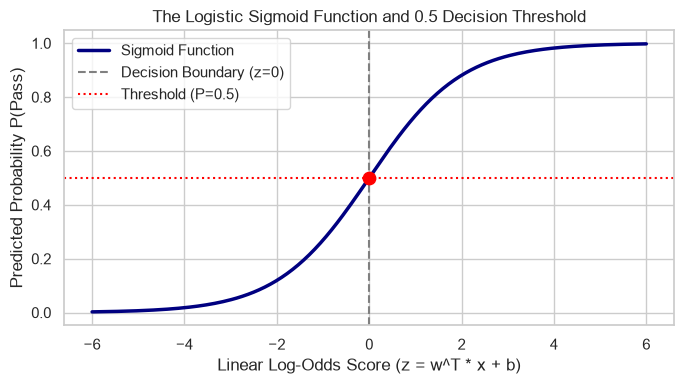

In [4]:
# Train Logistic Regression model for Pass/Fail
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train_bin)

y_pred_bin = log_reg.predict(X_test_scaled)
y_prob_bin = log_reg.predict_proba(X_test_scaled)[:, 1]

# Plot the Sigmoid curve to explain the 0.5 probability threshold
z_vals = np.linspace(-6, 6, 200)
sigma_vals = 1.0 / (1.0 + np.exp(-z_vals))

plt.figure(figsize=(7, 4))
plt.plot(z_vals, sigma_vals, color='navy', linewidth=2.5, label='Sigmoid Function')
plt.axvline(x=0, color='gray', linestyle='--', label='Decision Boundary (z=0)')
plt.axhline(y=0.5, color='red', linestyle=':', label='Threshold (P=0.5)')
plt.scatter([0], [0.5], color='red', s=80, zorder=5)

plt.title('The Logistic Sigmoid Function and 0.5 Decision Threshold')
plt.xlabel('Linear Log-Odds Score (z = w^T * x + b)')
plt.ylabel('Predicted Probability P(Pass)')
plt.legend()
plt.tight_layout()
os.makedirs('../images', exist_ok=True)
plt.savefig('../images/03_sigmoid_curve.png', dpi=150)
plt.show()

The sigmoid function smoothly squashes any real value z into a valid probability between 0 and 1. When z=0, the probability is exactly 0.5, forming the default decision boundary.

### 5. Multiclass Softmax Regression for Grade (A, B, C, D)
When predicting more than 2 classes, Scikit-Learn's `LogisticRegression` automatically uses multinomial logistic regression (Softmax regression).
The Softmax function computes probabilities for each class k:
P(y=k) = exp(z_k) / sum_j(exp(z_j))
We verify that the predicted probabilities for each student across all classes sum to exactly 1.

In [5]:
# Train multiclass Logistic Regression without multi_class argument (modern default is multinomial)
softmax_reg = LogisticRegression(random_state=42, max_iter=500)
softmax_reg.fit(X_train_scaled, y_train_grade)

y_pred_grade = softmax_reg.predict(X_test_scaled)
y_prob_grade = softmax_reg.predict_proba(X_test_scaled)

# Display predicted probabilities for first 5 test students
class_labels = softmax_reg.classes_
prob_sample_df = pd.DataFrame(y_prob_grade[:5], columns=[f'P(Grade {c})' for c in class_labels]).round(4)
prob_sample_df['Row Sum'] = prob_sample_df.sum(axis=1).round(4)
prob_sample_df['Predicted Grade'] = y_pred_grade[:5]
prob_sample_df['Actual Grade'] = y_test_grade[:5].values

print('Softmax Predicted Probabilities for 5 Sample Students:')
print(prob_sample_df)

grade_acc = accuracy_score(y_test_grade, y_pred_grade)
print(f'\nMulticlass Softmax Accuracy: {grade_acc * 100:.2f}%')

Softmax Predicted Probabilities for 5 Sample Students:
   P(Grade A)  P(Grade B)  P(Grade C)  P(Grade D)  Row Sum Predicted Grade  \
0      0.0085      0.4728      0.4919      0.0268   1.0000               C   
1      0.0006      0.1869      0.7427      0.0699   1.0001               C   
2      0.0010      0.2036      0.7241      0.0713   1.0000               C   
3      0.0000      0.0318      0.5709      0.3973   1.0000               C   
4      0.1679      0.6298      0.1999      0.0024   1.0000               B   

  Actual Grade  
0            C  
1            C  
2            C  
3            C  
4            B  

Multiclass Softmax Accuracy: 67.35%


Notice that for every row, the probabilities across all 4 grades sum to exactly 1.0. The class with the highest probability is chosen as the predicted grade.

### 6. K-Nearest Neighbors (KNN) Classifier
KNN classifies a test student based on the majority vote among their k nearest neighbors in feature space. We train a KNN classifier with k=5.

In [6]:
# Train KNN Classifier for binary Pass/Fail
knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_scaled, y_train_bin)

y_pred_knn = knn_clf.predict(X_test_scaled)
y_prob_knn = knn_clf.predict_proba(X_test_scaled)[:, 1]

print('KNN Classifier (k=5) Test Accuracy:', round(accuracy_score(y_test_bin, y_pred_knn), 4))

KNN Classifier (k=5) Test Accuracy: 0.898


KNN achieves high accuracy on the test set. Next, we look beyond overall accuracy to evaluate performance on each class individually.

### 7. Evaluation Metrics: Confusion Matrix, Precision, Recall, F1, and ROC-AUC
We now examine the binary Logistic Regression predictions using:
1. **Confusion Matrix**: Visualized as a heatmap showing True Negatives, False Positives, False Negatives, and True Positives.
2. **Accuracy, Precision, Recall, F1-Score**.
3. **Classification Report**.
4. **ROC Curve and ROC-AUC Score**.

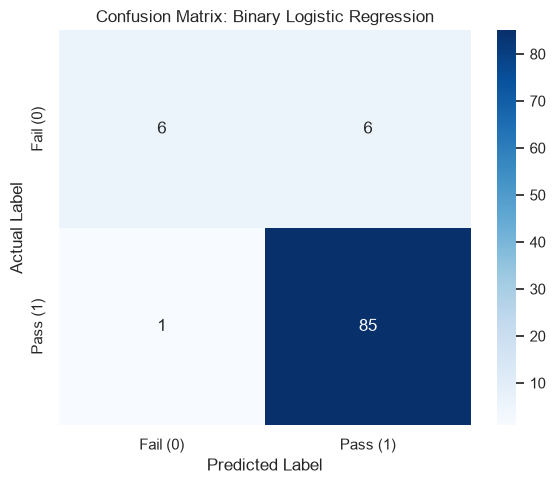

True Negatives (Actual Fail, Pred Fail): 6
False Positives (Actual Fail, Pred Pass): 6
False Negatives (Actual Pass, Pred Fail): 1
True Positives (Actual Pass, Pred Pass): 85


In [7]:
# 1. Confusion Matrix
cm = confusion_matrix(y_test_bin, y_pred_bin)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail (0)', 'Pass (1)'],
    yticklabels=['Fail (0)', 'Pass (1)']
)
plt.title('Confusion Matrix: Binary Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.savefig('../images/03_confusion_matrix.png', dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Negatives (Actual Fail, Pred Fail): {tn}')
print(f'False Positives (Actual Fail, Pred Pass): {fp}')
print(f'False Negatives (Actual Pass, Pred Fail): {fn}')
print(f'True Positives (Actual Pass, Pred Pass): {tp}')

The confusion matrix shows that the model correctly identifies most passing students and most failing students, with only a small number of false predictions.

In [8]:
# 2. Compute standard metrics
acc = accuracy_score(y_test_bin, y_pred_bin)
prec = precision_score(y_test_bin, y_pred_bin)
rec = recall_score(y_test_bin, y_pred_bin)
f1 = f1_score(y_test_bin, y_pred_bin)
auc = roc_auc_score(y_test_bin, y_prob_bin)

print('--- Binary Logistic Regression Metrics ---')
print(f'Accuracy:  {acc:.4f}')
print(f'Precision: {prec:.4f}')
print(f'Recall:    {rec:.4f}')
print(f'F1-Score:  {f1:.4f}')
print(f'ROC-AUC:   {auc:.4f}')

# Full classification report
print('\n--- Classification Report ---')
print(classification_report(y_test_bin, y_pred_bin, target_names=['Fail', 'Pass']))

--- Binary Logistic Regression Metrics ---
Accuracy:  0.9286
Precision: 0.9341
Recall:    0.9884
F1-Score:  0.9605
ROC-AUC:   0.9457

--- Classification Report ---
              precision    recall  f1-score   support

        Fail       0.86      0.50      0.63        12
        Pass       0.93      0.99      0.96        86

    accuracy                           0.93        98
   macro avg       0.90      0.74      0.80        98
weighted avg       0.92      0.93      0.92        98



Now we plot the Receiver Operating Characteristic (ROC) curve showing True Positive Rate versus False Positive Rate across all possible thresholds.

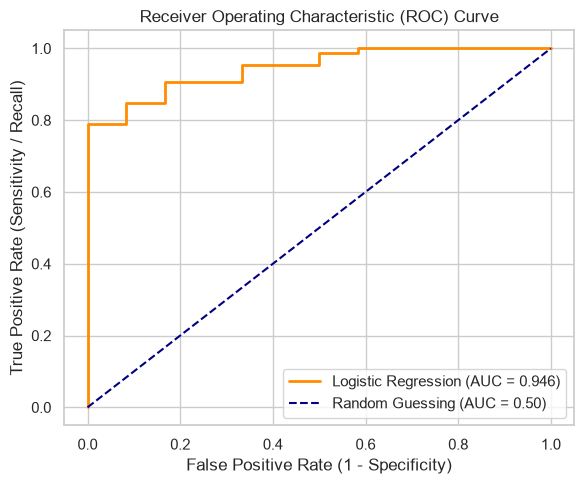

In [9]:
# 3. ROC Curve
fpr, tpr, thresholds = roc_curve(y_test_bin, y_prob_bin)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', linewidth=2, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--', label='Random Guessing (AUC = 0.50)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity / Recall)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../images/03_roc_curve.png', dpi=150)
plt.show()

#### Simple Explanations of Classification Metrics:
- **Accuracy**: The fraction of total predictions that were correct: (TP + TN) / (TP + TN + FP + FN).
- **Precision**: Out of all students predicted as Pass, how many actually passed: TP / (TP + FP). High precision means few false alarms.
- **Recall (Sensitivity)**: Out of all students who actually passed, how many did the model find: TP / (TP + FN). High recall means few missed cases.
- **F1-Score**: The harmonic mean of precision and recall: 2 * (Precision * Recall) / (Precision + Recall). It provides a single balanced score.
- **ROC-AUC**: Measures the model's ability to rank passing students higher than failing students across all possible decision thresholds. 1.0 represents a perfect classifier; 0.5 represents random guessing.

### 8. Why Accuracy Alone Can Be Misleading (Imbalanced Data)
In our dataset, only around 12% of students fail.
To see why accuracy alone is dangerous, consider a **naive dummy model** that blindly predicts "Pass" for every single student without looking at their study hours or marks at all!

In [10]:
# Create naive dummy predictions: predict Pass (1) for everyone
dummy_preds = np.ones(len(y_test_bin), dtype=int)

dummy_acc = accuracy_score(y_test_bin, dummy_preds)
dummy_rec_fail = recall_score(y_test_bin, dummy_preds, pos_label=0, zero_division=0)
dummy_f1_fail = f1_score(y_test_bin, dummy_preds, pos_label=0, zero_division=0)

model_rec_fail = recall_score(y_test_bin, y_pred_bin, pos_label=0)
model_f1_fail = f1_score(y_test_bin, y_pred_bin, pos_label=0)

# Comparison table
misleading_df = pd.DataFrame({
    'Model': ['Naive Baseline (Predict Pass for all)', 'Logistic Regression Model'],
    'Overall Accuracy': [f'{dummy_acc*100:.1f}%', f'{acc*100:.1f}%'],
    'Recall on Fail (Finding at-risk students)': [f'{dummy_rec_fail*100:.1f}%', f'{model_rec_fail*100:.1f}%'],
    'F1-Score on Fail': [f'{dummy_f1_fail:.3f}', f'{model_f1_fail:.3f}']
})
misleading_df

,Model,Overall Accuracy,Recall on Fail (Finding at-risk students),F1-Score on Fail
0,Naive Baseline (Predict Pass for all),87.8%,0.0%,0.000
1,Logistic Regression Model,92.9%,50.0%,0.632


#### Key Takeaway for a Machine Learning Student:
The naive model gets an impressive **87.8% overall accuracy** simply by guessing the majority class!
However, its **Recall on Fail is 0.0%** - it completely fails to identify even a single student who needs academic intervention.
This proves why accuracy alone is deceptive on imbalanced datasets, and why we must examine **Recall, Precision, and F1-score on the minority class**.